In [4]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats


# Plotting
set_matplotlib_formats("retina")

plt.style.use(
    "https://raw.githubusercontent.com/"
    "ksingh1121/python-plot-style/main/physics.mplstyle"
)


================ CENTERS ================

 z_cm  blaze_px       x_px       y_px  x_err_px  y_err_px  sigma_x_px  sigma_y_px
    0        12 639.580376 195.199346  0.065845  0.087555   33.660653   44.005588
    0        16 388.672584 201.113370  0.069231  0.085899   36.225904   44.208573
    0        24 138.717185 207.681613  0.069879  0.088621   35.784755   44.572129
    1        12 737.097084 188.729892  0.044631  0.057830   22.321616   28.930561
    1        16 487.443545 194.802439  0.048693  0.060629   24.148018   30.061436
    1        24 235.058812 199.952556  0.050678  0.063371   24.135928   30.174519
    2        12 730.516616 181.931943  0.028047  0.032859   20.624130   24.162439
    2        16 480.860887 187.957807  0.029849  0.034179   21.177130   24.249197
    2        24 229.302064 193.660633  0.029744  0.033832   21.269173   24.192339
    3        12 731.610495 177.823356  0.017919  0.019966   20.107055   22.404461
    3        16 480.937150 182.753258  0.018942  0.020

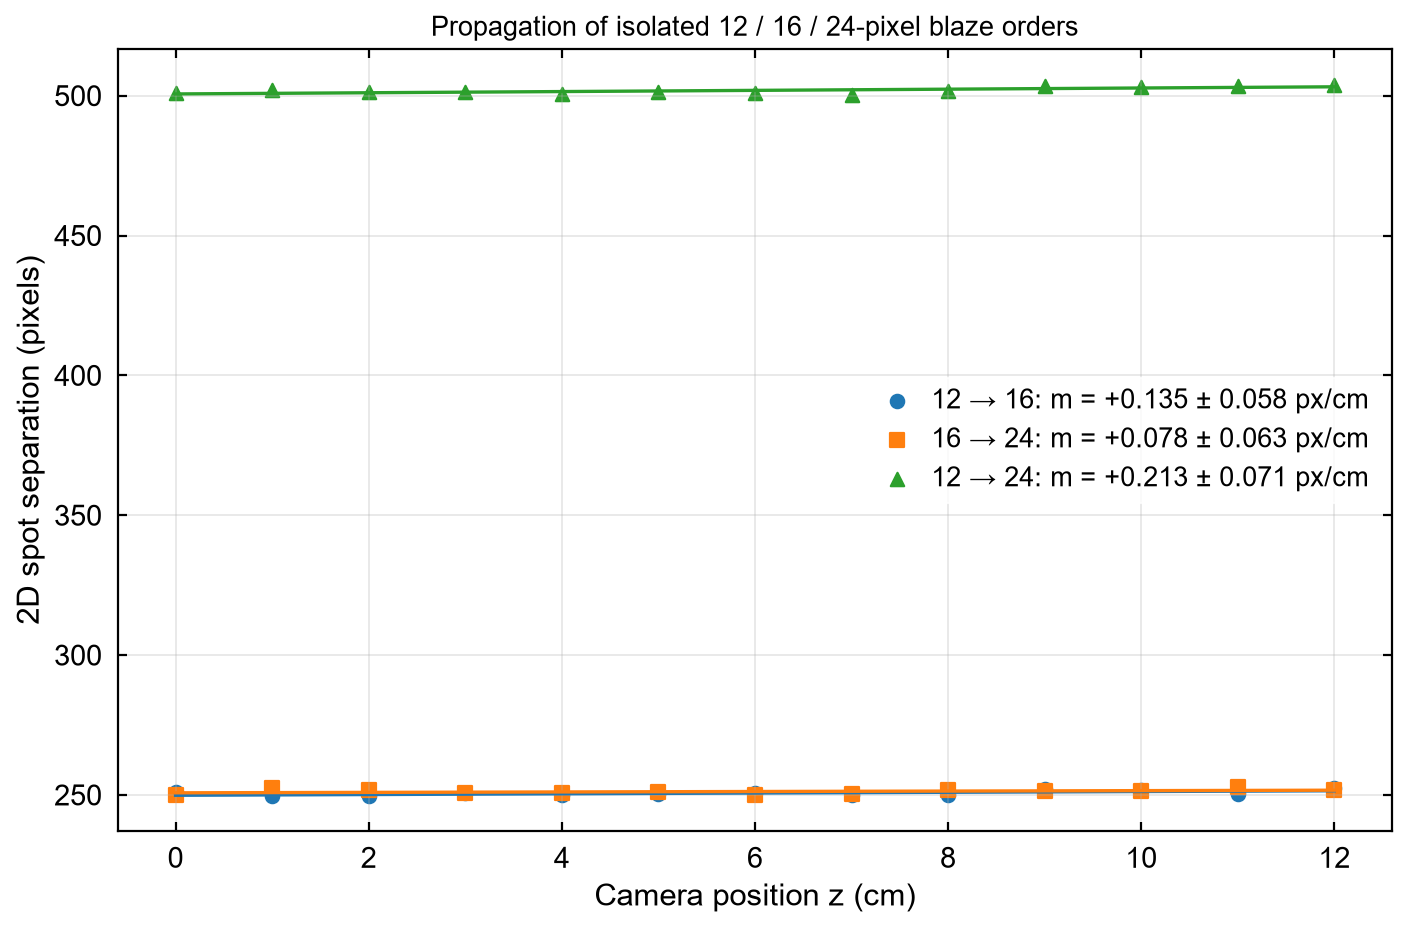

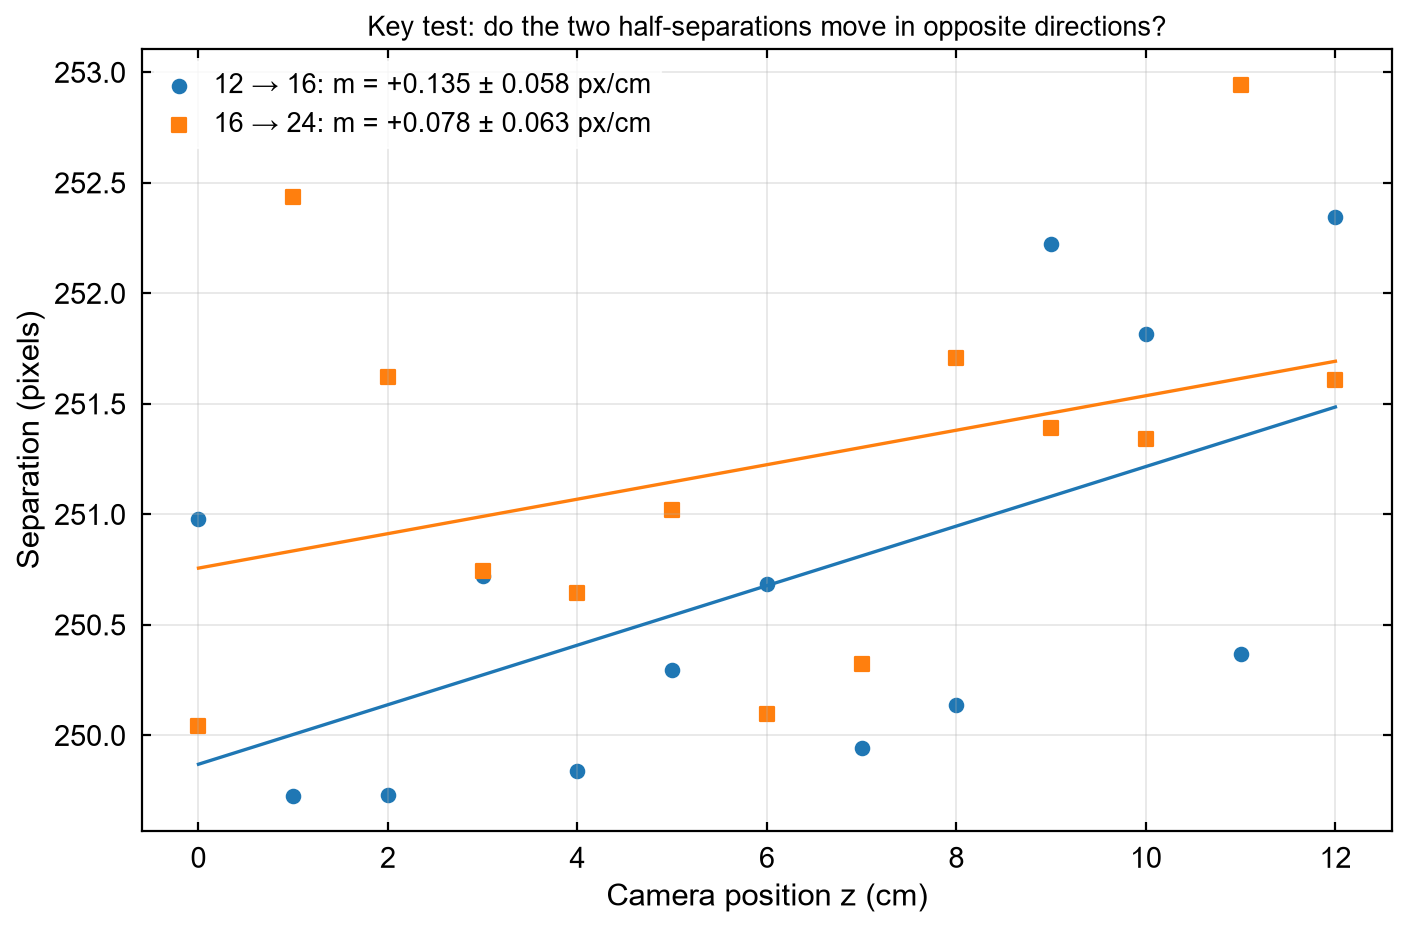

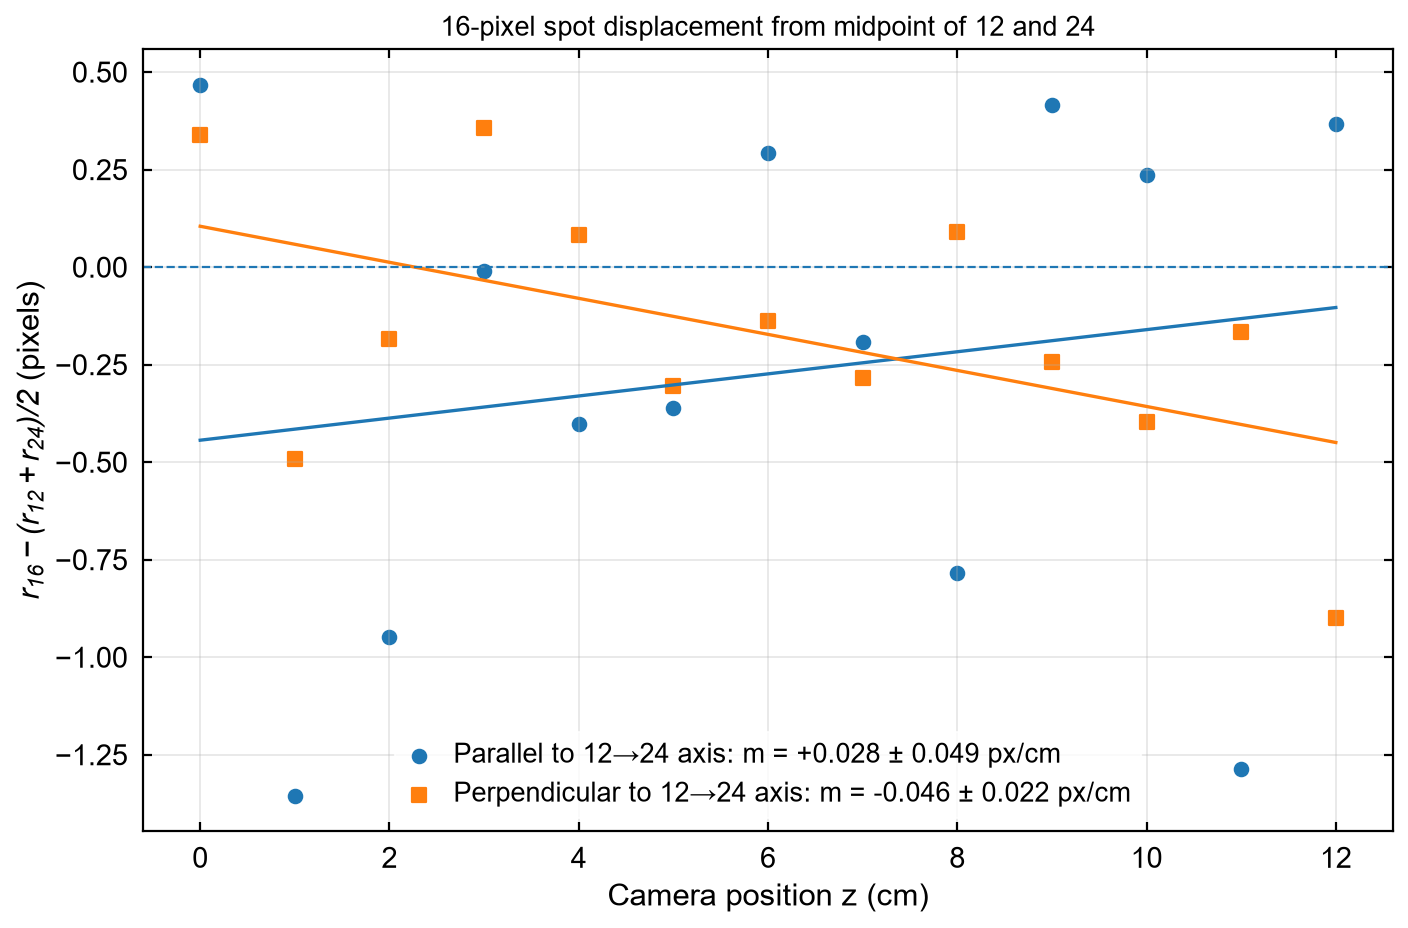

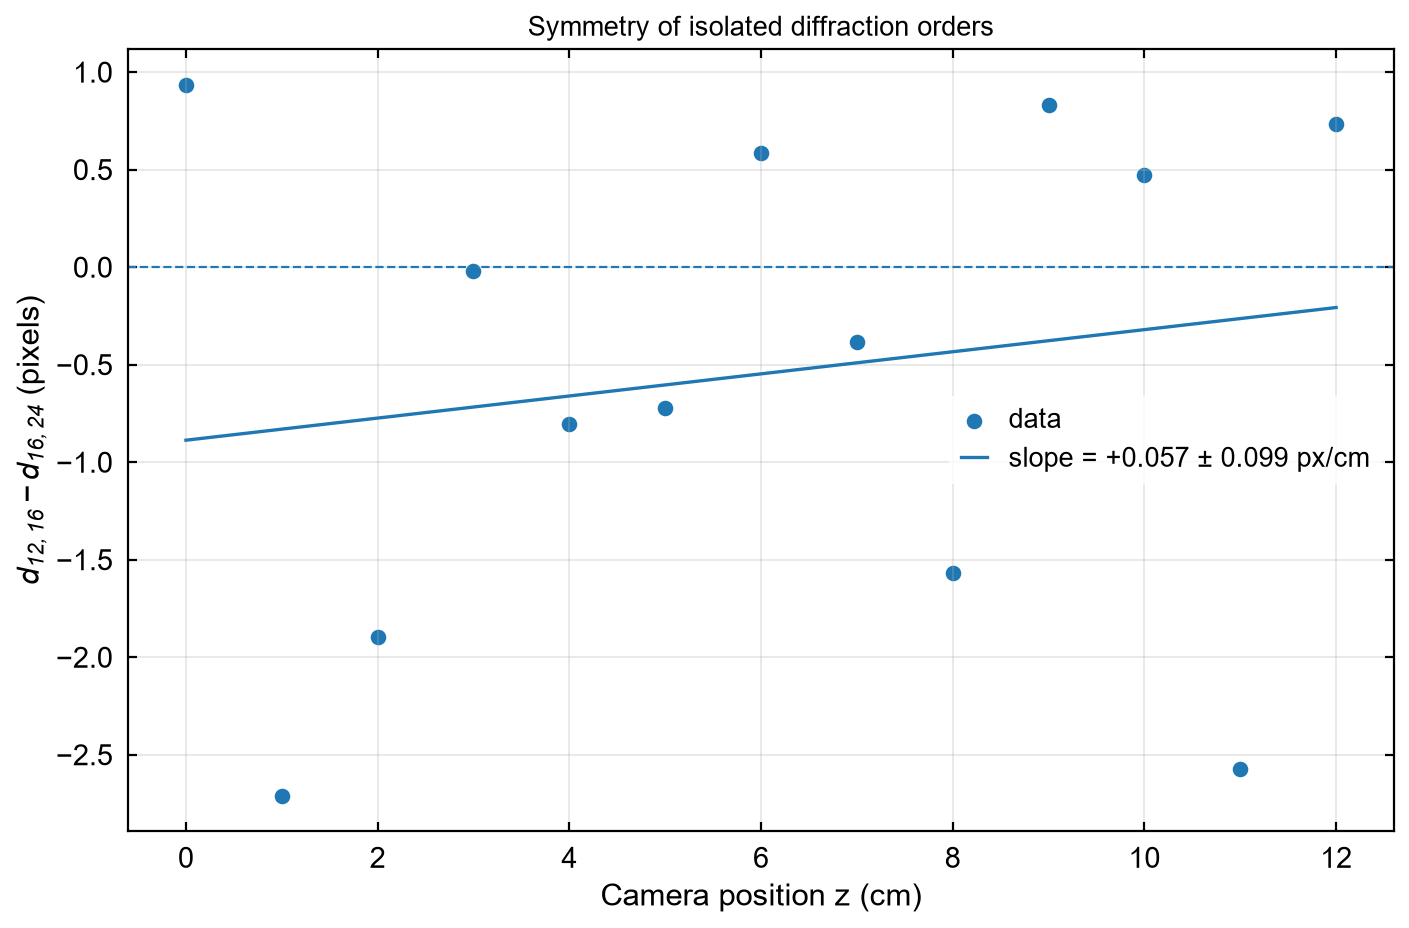



PHYSICAL SUMMARY

12→16 slope = +0.13468 ± 0.05844 px/cm
16→24 slope = +0.07800 ± 0.06319 px/cm
12→24 slope = +0.21260 ± 0.07108 px/cm

Midpoint-parallel slope = +0.02834 ± 0.04940 px/cm
Asymmetry slope = +0.05669 ± 0.09879 px/cm

Mean absolute midpoint error = 0.548 px

If the isolated-order test is clean, we expect:
  1. d12-16 and d16-24 slopes to be similar,
     NOT equal-and-opposite.
  2. midpoint_parallel slope ≈ 0.
  3. asymmetry slope ≈ 0.
  4. Any common change in both half-distances then reflects
     real optical propagation / L1 longitudinal placement,
     rather than motion of the 16-pixel order caused by
     the simultaneous SLM phase pattern.

Finished.


In [6]:
# ============================================================
# ISOLATED 12 / 16 / 24 PIXEL BLAZE PROPAGATION ANALYSIS
#
# Expected filenames:
#   z0-12.bmp, z0-16.bmp, z0-24.bmp
#   z1-12.bmp, z1-16.bmp, z1-24.bmp
#   ...
#   z12-12.bmp, z12-16.bmp, z12-24.bmp
#
# z is assumed to be in cm.
# ============================================================

from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from scipy.ndimage import gaussian_filter
from scipy.optimize import curve_fit


# ============================================================
# USER SETTINGS
# ============================================================

DATA_DIR = Path(r"C:\Users\admin\Desktop\Projects\SLM\SLM tests\Data\300 mm longitudinal\final locked position- one spot at a time to avoid phase intermod")

# z values to analyse
Z_VALUES = np.arange(0, 13, 1)       # z0 ... z12, in cm

BLAZES = [12, 16, 24]

# Approximate uncertainty assigned to each fitted center.
# You can use 1 px for these isolated spots, or 2.5 px if you
# want to be conservative and compare directly to old analysis.
CENTER_SIGMA_PX = 1.0

# Smoothing suppresses the fine vertical interference fringes,
# allowing us to fit the overall optical spot envelope.
SMOOTH_SIGMA_PX = 5.0

# Half-width of square ROI around automatically detected spot
ROI_HALF_SIZE = 90

# If True, show every fitted image.
SHOW_EVERY_FIT = False


# ============================================================
# HELPER FUNCTIONS
# ============================================================

def load_image(path):
    """Load BMP as float array."""
    return np.asarray(Image.open(path), dtype=float)


def gaussian_2d(coords, amplitude, x0, y0, sx, sy, offset):
    """
    Axis-aligned 2D Gaussian.
    We are fitting the smoothed envelope, not the raw fringes.
    """
    x, y = coords

    g = (
        offset
        + amplitude
        * np.exp(
            -(
                (x - x0)**2 / (2 * sx**2)
                + (y - y0)**2 / (2 * sy**2)
            )
        )
    )

    return g.ravel()


def fit_spot_center(path, show=False):
    """
    Find center of overall spot envelope.

    Procedure:
       1. Load image
       2. Smooth image to suppress fine fringes
       3. Find brightest region
       4. Crop ROI
       5. Fit smoothed envelope to 2D Gaussian

    Returns:
        x0, y0, sx, sy
    """

    image = load_image(path)

    # --------------------------------------------------------
    # Estimate/subtract background
    # --------------------------------------------------------

    # Robust low percentile because most image is dark
    background = np.percentile(image, 10)

    clean = image - background
    clean[clean < 0] = 0

    # --------------------------------------------------------
    # Smooth out small-scale diffraction/interference fringes
    # --------------------------------------------------------

    smooth = gaussian_filter(clean, sigma=SMOOTH_SIGMA_PX)

    # --------------------------------------------------------
    # Initial estimate = maximum of smoothed image
    # --------------------------------------------------------

    y_peak, x_peak = np.unravel_index(
        np.argmax(smooth),
        smooth.shape
    )

    ny, nx = smooth.shape

    x_min = max(0, x_peak - ROI_HALF_SIZE)
    x_max = min(nx, x_peak + ROI_HALF_SIZE + 1)

    y_min = max(0, y_peak - ROI_HALF_SIZE)
    y_max = min(ny, y_peak + ROI_HALF_SIZE + 1)

    roi = smooth[y_min:y_max, x_min:x_max]

    yy, xx = np.indices(roi.shape)

    # Convert ROI coordinates to full-camera coordinates
    xx_full = xx + x_min
    yy_full = yy + y_min

    # --------------------------------------------------------
    # Initial Gaussian parameters
    # --------------------------------------------------------

    amp0 = roi.max() - np.median(roi)

    p0 = [
        amp0,
        float(x_peak),
        float(y_peak),
        20.0,
        20.0,
        float(np.median(roi))
    ]

    bounds_lower = [
        0,
        x_min,
        y_min,
        2,
        2,
        -np.inf
    ]

    bounds_upper = [
        np.inf,
        x_max,
        y_max,
        ROI_HALF_SIZE,
        ROI_HALF_SIZE,
        np.inf
    ]

    # --------------------------------------------------------
    # Gaussian fit
    # --------------------------------------------------------

    popt, pcov = curve_fit(
        gaussian_2d,
        (xx_full, yy_full),
        roi.ravel(),
        p0=p0,
        bounds=(bounds_lower, bounds_upper),
        maxfev=30000
    )

    amplitude, x0, y0, sx, sy, offset = popt

    perr = np.sqrt(np.diag(pcov))

    x0_err = perr[1]
    y0_err = perr[2]

    return x0, y0, x0_err, y0_err, sx, sy

    # --------------------------------------------------------
    # Optional fit display
    # --------------------------------------------------------

    if show:

        fit_roi = gaussian_2d(
            (xx_full, yy_full),
            *popt
        ).reshape(roi.shape)

        plt.figure(figsize=(8, 5))

        plt.imshow(
            image,
            origin="upper"
        )

        plt.scatter(
            [x0],
            [y0],
            marker="+",
            s=150,
            linewidths=2,
            label=f"center = ({x0:.2f}, {y0:.2f})"
        )

        plt.xlim(x_min, x_max)
        plt.ylim(y_max, y_min)

        plt.title(path.name)
        plt.legend()
        plt.tight_layout()
        plt.show()

    return x0, y0, sx, sy


def distance(p1, p2):
    """2D Euclidean distance."""
    p1 = np.asarray(p1)
    p2 = np.asarray(p2)

    return np.linalg.norm(p2 - p1)


def linear_fit(x, y):
    """
    Fit:
        y = m*x + b

    Returns slope, intercept and 1-sigma uncertainties.
    """

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    coeff, cov = np.polyfit(
        x,
        y,
        1,
        cov=True
    )

    m, b = coeff

    m_err = np.sqrt(cov[0, 0])
    b_err = np.sqrt(cov[1, 1])

    return m, b, m_err, b_err


# ============================================================
# FIND ALL CENTERS
# ============================================================

center_rows = []

for z in Z_VALUES:

    for blaze in BLAZES:

        filename = f"z{z}-{blaze}.bmp"
        path = DATA_DIR / filename

        if not path.exists():
            print(f"WARNING: missing {filename}")
            continue

        x0, y0, x0_err, y0_err, sx, sy = fit_spot_center(
            path,
            show=SHOW_EVERY_FIT
        )

        center_rows.append(
    {
        "z_cm": z,
        "blaze_px": blaze,
        "x_px": x0,
        "y_px": y0,
        "x_err_px": x0_err,
        "y_err_px": y0_err,
        "sigma_x_px": sx,
        "sigma_y_px": sy,
    }
)


centers = pd.DataFrame(center_rows)

print("\n================ CENTERS ================\n")
print(centers.to_string(index=False))


# ============================================================
# CALCULATE DISTANCES + MIDPOINT ERROR
# ============================================================

analysis_rows = []

for z in sorted(centers["z_cm"].unique()):

    sub = centers[centers["z_cm"] == z]

    if not all(
        blaze in sub["blaze_px"].values
        for blaze in BLAZES
    ):
        print(f"Skipping z={z}: incomplete triplet")
        continue

    p12 = (
        sub[sub["blaze_px"] == 12][["x_px", "y_px"]]
        .iloc[0]
        .to_numpy(dtype=float)
    )

    p16 = (
        sub[sub["blaze_px"] == 16][["x_px", "y_px"]]
        .iloc[0]
        .to_numpy(dtype=float)
    )

    p24 = (
        sub[sub["blaze_px"] == 24][["x_px", "y_px"]]
        .iloc[0]
        .to_numpy(dtype=float)
    )

    # --------------------------------------------------------
    # Pairwise distances
    # --------------------------------------------------------

    d12_16 = distance(p12, p16)
    d16_24 = distance(p16, p24)
    d12_24 = distance(p12, p24)

    # --------------------------------------------------------
    # Geometrical midpoint of outer spots
    # --------------------------------------------------------

    midpoint = 0.5 * (p12 + p24)

    midpoint_vector = p16 - midpoint

    midpoint_error = np.linalg.norm(midpoint_vector)

    # --------------------------------------------------------
    # Define axis joining the 12 and 24 spots
    # --------------------------------------------------------

    outer_vector = p24 - p12
    outer_distance = np.linalg.norm(outer_vector)

    u_parallel = outer_vector / outer_distance

    # perpendicular unit vector
    u_perp = np.array([
        -u_parallel[1],
        u_parallel[0]
    ])

    # Signed displacement of 16th-order spot from midpoint
    midpoint_parallel = np.dot(
        midpoint_vector,
        u_parallel
    )

    midpoint_perpendicular = np.dot(
        midpoint_vector,
        u_perp
    )

    # --------------------------------------------------------
    # Half-distance asymmetry
    #
    # If 16 lies exactly halfway:
    #
    #     d12_16 - d16_24 = 0
    #
    # --------------------------------------------------------

    asymmetry = d12_16 - d16_24

    analysis_rows.append(
        {
            "z_cm": z,

            "x12": p12[0],
            "y12": p12[1],

            "x16": p16[0],
            "y16": p16[1],

            "x24": p24[0],
            "y24": p24[1],

            "d12_16_px": d12_16,
            "d16_24_px": d16_24,
            "d12_24_px": d12_24,

            "midpoint_error_px": midpoint_error,

            "midpoint_parallel_px": midpoint_parallel,
            "midpoint_perpendicular_px": midpoint_perpendicular,

            "distance_asymmetry_px": asymmetry,
        }
    )


results = pd.DataFrame(analysis_rows)

print("\n================ DISTANCE ANALYSIS ================\n")
print(results.to_string(index=False))


# ============================================================
# SAVE CSV FILES
# ============================================================

centers.to_csv(
    DATA_DIR / "isolated_spot_centers.csv",
    index=False
)

results.to_csv(
    DATA_DIR / "isolated_spot_analysis.csv",
    index=False
)


# ============================================================
# LINEAR FITS
# ============================================================

z = results["z_cm"].to_numpy()

quantities = {
    "d12-16":
        results["d12_16_px"].to_numpy(),

    "d16-24":
        results["d16_24_px"].to_numpy(),

    "d12-24":
        results["d12_24_px"].to_numpy(),

    "midpoint parallel":
        results["midpoint_parallel_px"].to_numpy(),

    "midpoint perpendicular":
        results["midpoint_perpendicular_px"].to_numpy(),

    "distance asymmetry":
        results["distance_asymmetry_px"].to_numpy(),
}


fit_results = {}


print("\n")
print("=" * 75)
print("LINEAR FIT RESULTS")
print("=" * 75)

for name, values in quantities.items():

    m, b, m_err, b_err = linear_fit(
        z,
        values
    )

    fit_results[name] = {
        "slope": m,
        "slope_err": m_err,
        "intercept": b,
        "intercept_err": b_err
    }

    print(
        f"{name:25s}: "
        f"slope = {m:+.5f} ± {m_err:.5f} px/cm"
    )


# ============================================================
# PLOT 1:
# THREE DISTANCES
# ============================================================

plt.figure(figsize=(9, 6))

for name, column, marker in [

    ("12 → 16", "d12_16_px", "o"),
    ("16 → 24", "d16_24_px", "s"),
    ("12 → 24", "d12_24_px", "^"),
]:

    y = results[column].to_numpy()

    m, b, m_err, b_err = linear_fit(z, y)

    plt.scatter(
        z,
        y,
        marker=marker,
        label=f"{name}: m = {m:+.3f} ± {m_err:.3f} px/cm"
    )

    z_fit = np.linspace(z.min(), z.max(), 300)

    plt.plot(
        z_fit,
        m*z_fit + b
    )


plt.xlabel("Camera position z (cm)")
plt.ylabel("2D spot separation (pixels)")
plt.title("Propagation of isolated 12 / 16 / 24-pixel blaze orders")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    DATA_DIR / "isolated_distances_vs_z.png",
    dpi=200
)

plt.show()


# ============================================================
# PLOT 2:
# 12-16 AND 16-24 ONLY
#
# This is the most direct comparison to your old result.
# ============================================================

plt.figure(figsize=(9, 6))

for name, column, marker in [

    ("12 → 16", "d12_16_px", "o"),
    ("16 → 24", "d16_24_px", "s"),
]:

    y = results[column].to_numpy()

    m, b, m_err, b_err = linear_fit(z, y)

    plt.scatter(
        z,
        y,
        marker=marker,
        label=f"{name}: m = {m:+.3f} ± {m_err:.3f} px/cm"
    )

    z_fit = np.linspace(z.min(), z.max(), 300)

    plt.plot(
        z_fit,
        m*z_fit + b
    )


plt.xlabel("Camera position z (cm)")
plt.ylabel("Separation (pixels)")

plt.title(
    "Key test: do the two half-separations "
    "move in opposite directions?"
)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    DATA_DIR / "isolated_half_distances_vs_z.png",
    dpi=200
)

plt.show()


# ============================================================
# PLOT 3:
# MIDPOINT ERROR
# ============================================================

plt.figure(figsize=(9, 6))


for name, column, marker in [

    (
        "Parallel to 12→24 axis",
        "midpoint_parallel_px",
        "o"
    ),

    (
        "Perpendicular to 12→24 axis",
        "midpoint_perpendicular_px",
        "s"
    ),
]:

    y = results[column].to_numpy()

    m, b, m_err, b_err = linear_fit(z, y)

    plt.scatter(
        z,
        y,
        marker=marker,
        label=f"{name}: m = {m:+.3f} ± {m_err:.3f} px/cm"
    )

    z_fit = np.linspace(z.min(), z.max(), 300)

    plt.plot(
        z_fit,
        m*z_fit + b
    )


plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.xlabel("Camera position z (cm)")

plt.ylabel(
    r"$r_{16} - (r_{12}+r_{24})/2$ (pixels)"
)

plt.title(
    "16-pixel spot displacement from midpoint of 12 and 24"
)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    DATA_DIR / "isolated_midpoint_error_vs_z.png",
    dpi=200
)

plt.show()


# ============================================================
# PLOT 4:
# DISTANCE ASYMMETRY
#
# d12-16 - d16-24
#
# Ideal symmetric geometry -> approximately zero
# ============================================================

asym = results["distance_asymmetry_px"].to_numpy()

m, b, m_err, b_err = linear_fit(z, asym)

plt.figure(figsize=(9, 6))

plt.scatter(
    z,
    asym,
    label="data"
)

z_fit = np.linspace(
    z.min(),
    z.max(),
    300
)

plt.plot(
    z_fit,
    m*z_fit+b,
    label=f"slope = {m:+.3f} ± {m_err:.3f} px/cm"
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.xlabel("Camera position z (cm)")

plt.ylabel(
    r"$d_{12,16} - d_{16,24}$ (pixels)"
)

plt.title(
    "Symmetry of isolated diffraction orders"
)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    DATA_DIR / "isolated_distance_asymmetry_vs_z.png",
    dpi=200
)

plt.show()


# ============================================================
# SUMMARY
# ============================================================

m1 = fit_results["d12-16"]["slope"]
e1 = fit_results["d12-16"]["slope_err"]

m2 = fit_results["d16-24"]["slope"]
e2 = fit_results["d16-24"]["slope_err"]

m_outer = fit_results["d12-24"]["slope"]
e_outer = fit_results["d12-24"]["slope_err"]

m_mid = fit_results["midpoint parallel"]["slope"]
e_mid = fit_results["midpoint parallel"]["slope_err"]

m_asym = fit_results["distance asymmetry"]["slope"]
e_asym = fit_results["distance asymmetry"]["slope_err"]


print("\n")
print("=" * 75)
print("PHYSICAL SUMMARY")
print("=" * 75)

print(
    f"\n12→16 slope = {m1:+.5f} ± {e1:.5f} px/cm"
)

print(
    f"16→24 slope = {m2:+.5f} ± {e2:.5f} px/cm"
)

print(
    f"12→24 slope = {m_outer:+.5f} ± {e_outer:.5f} px/cm"
)

print(
    f"\nMidpoint-parallel slope = "
    f"{m_mid:+.5f} ± {e_mid:.5f} px/cm"
)

print(
    f"Asymmetry slope = "
    f"{m_asym:+.5f} ± {e_asym:.5f} px/cm"
)

print(
    "\nMean absolute midpoint error = "
    f"{np.mean(np.abs(results['midpoint_parallel_px'])):.3f} px"
)

print(
    "\nIf the isolated-order test is clean, we expect:"
)

print(
    "  1. d12-16 and d16-24 slopes to be similar,"
)

print(
    "     NOT equal-and-opposite."
)

print(
    "  2. midpoint_parallel slope ≈ 0."
)

print(
    "  3. asymmetry slope ≈ 0."
)

print(
    "  4. Any common change in both half-distances then reflects"
)

print(
    "     real optical propagation / L1 longitudinal placement,"
)

print(
    "     rather than motion of the 16-pixel order caused by"
)

print(
    "     the simultaneous SLM phase pattern."
)

print("\nFinished.")


================ CENTERS ================

 z_cm  blaze_px       x_px       y_px  x_formal_err_px  y_formal_err_px  x_err_px  y_err_px  sigma_x_px  sigma_y_px
    0        12 639.580376 195.199346         0.065845         0.087555  0.504317  0.507608   33.660653   44.005588
    0        16 388.672584 201.113370         0.069231         0.085899  0.504770  0.507325   36.225904   44.208573
    0        24 138.717185 207.681613         0.069879         0.088621  0.504859  0.507793   35.784755   44.572129
    1        12 737.097084 188.729892         0.044631         0.057830  0.501988  0.503333   22.321616   28.930561
    1        16 487.443545 194.802439         0.048693         0.060629  0.502365  0.503662   24.148018   30.061436
    1        24 235.058812 199.952556         0.050678         0.063371  0.502562  0.504000   24.135928   30.174519
    2        12 730.516616 181.931943         0.028047         0.032859  0.500786  0.501079   20.624130   24.162439
    2        16 480.860887 1

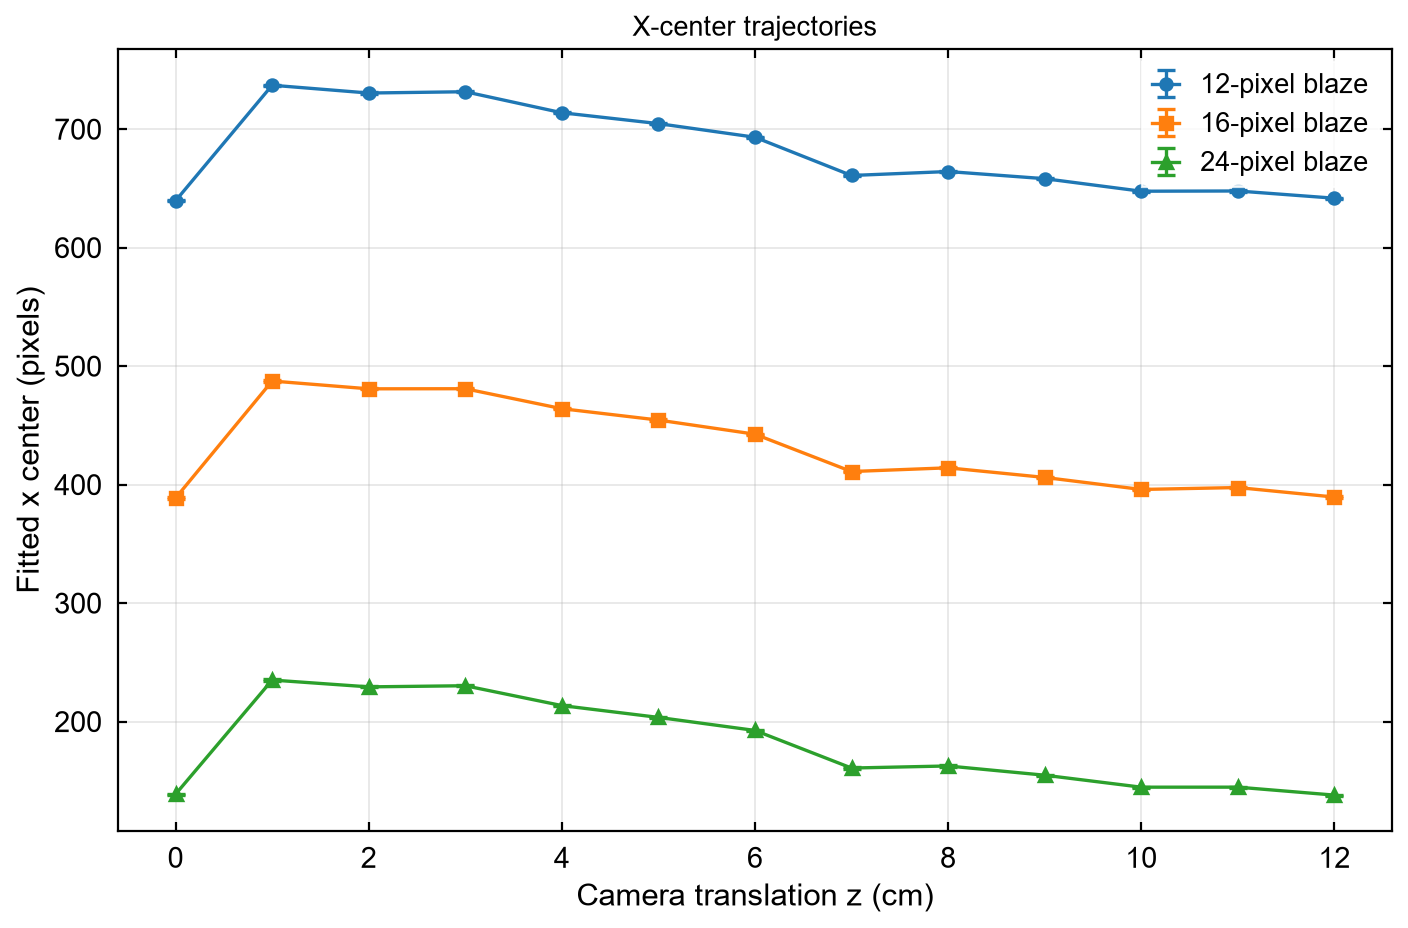

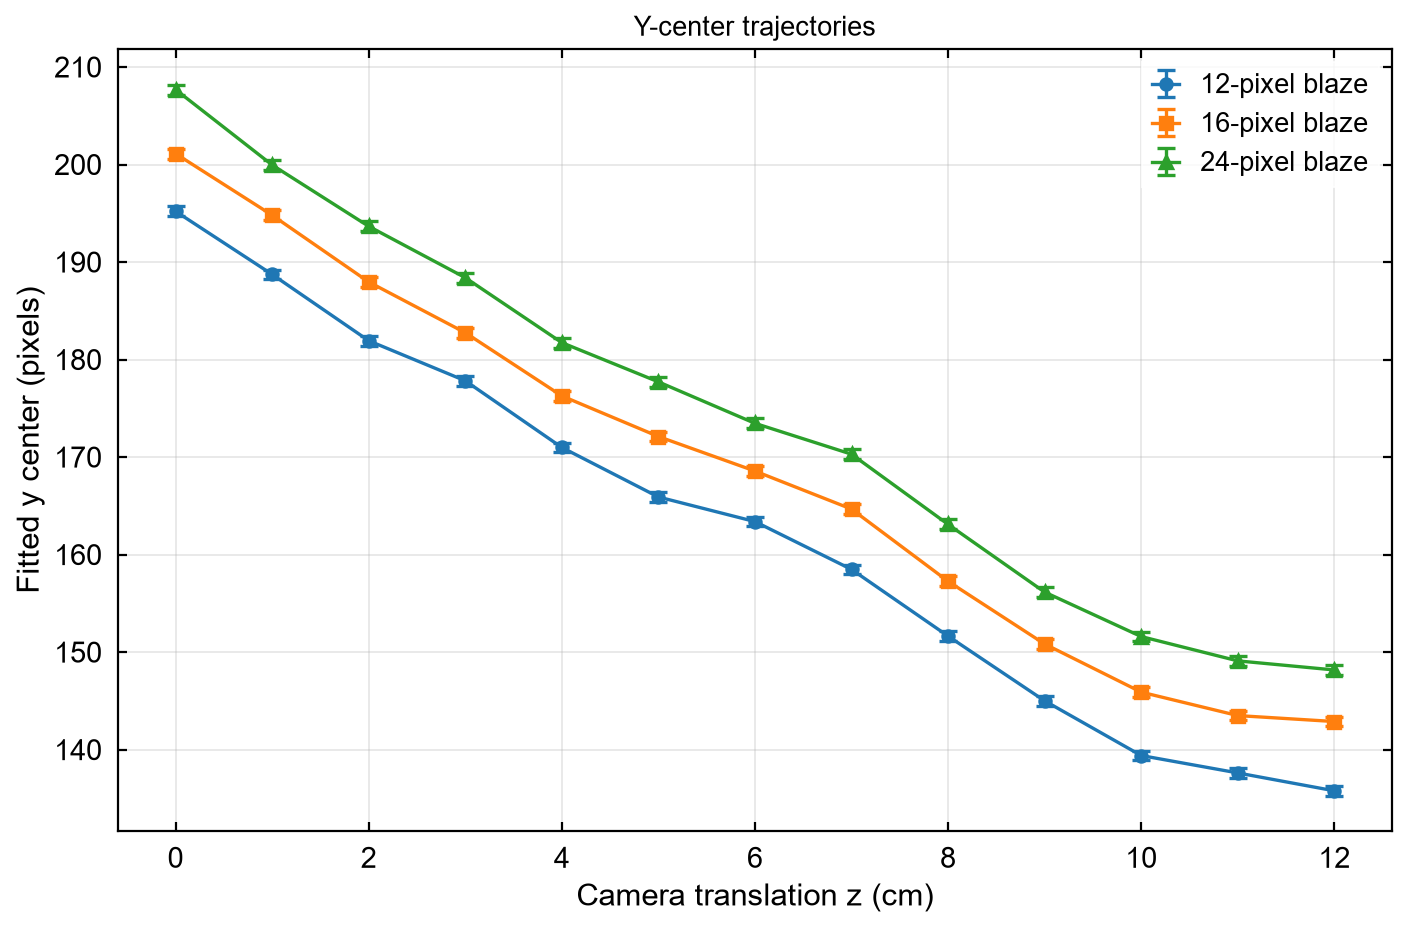



WEIGHTED LINEAR FIT RESULTS
d12-16                   : slope = +0.13524 ± 0.05255 px/cm   reduced chi² = 1.239
d16-24                   : slope = +0.07802 ± 0.05256 px/cm   reduced chi² = 1.446
d12-24                   : slope = +0.21317 ± 0.05256 px/cm   reduced chi² = 1.835
midpoint parallel        : slope = +0.02863 ± 0.04552 px/cm   reduced chi² = 1.178
midpoint perpendicular   : slope = -0.04619 ± 0.04559 px/cm   reduced chi² = 0.242
distance asymmetry       : slope = +0.05725 ± 0.09104 px/cm   reduced chi² = 1.178


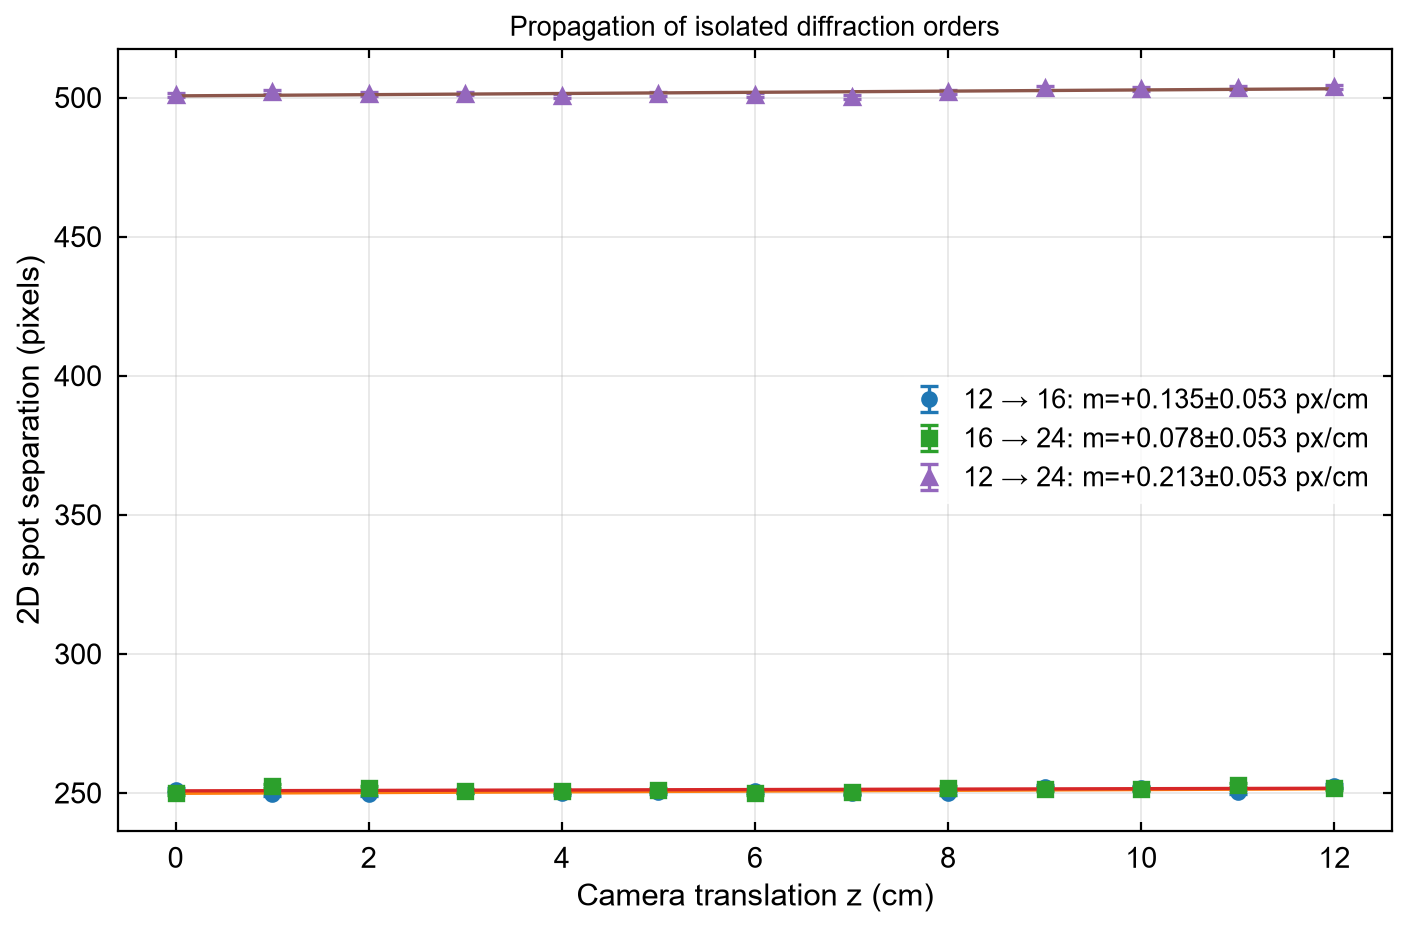

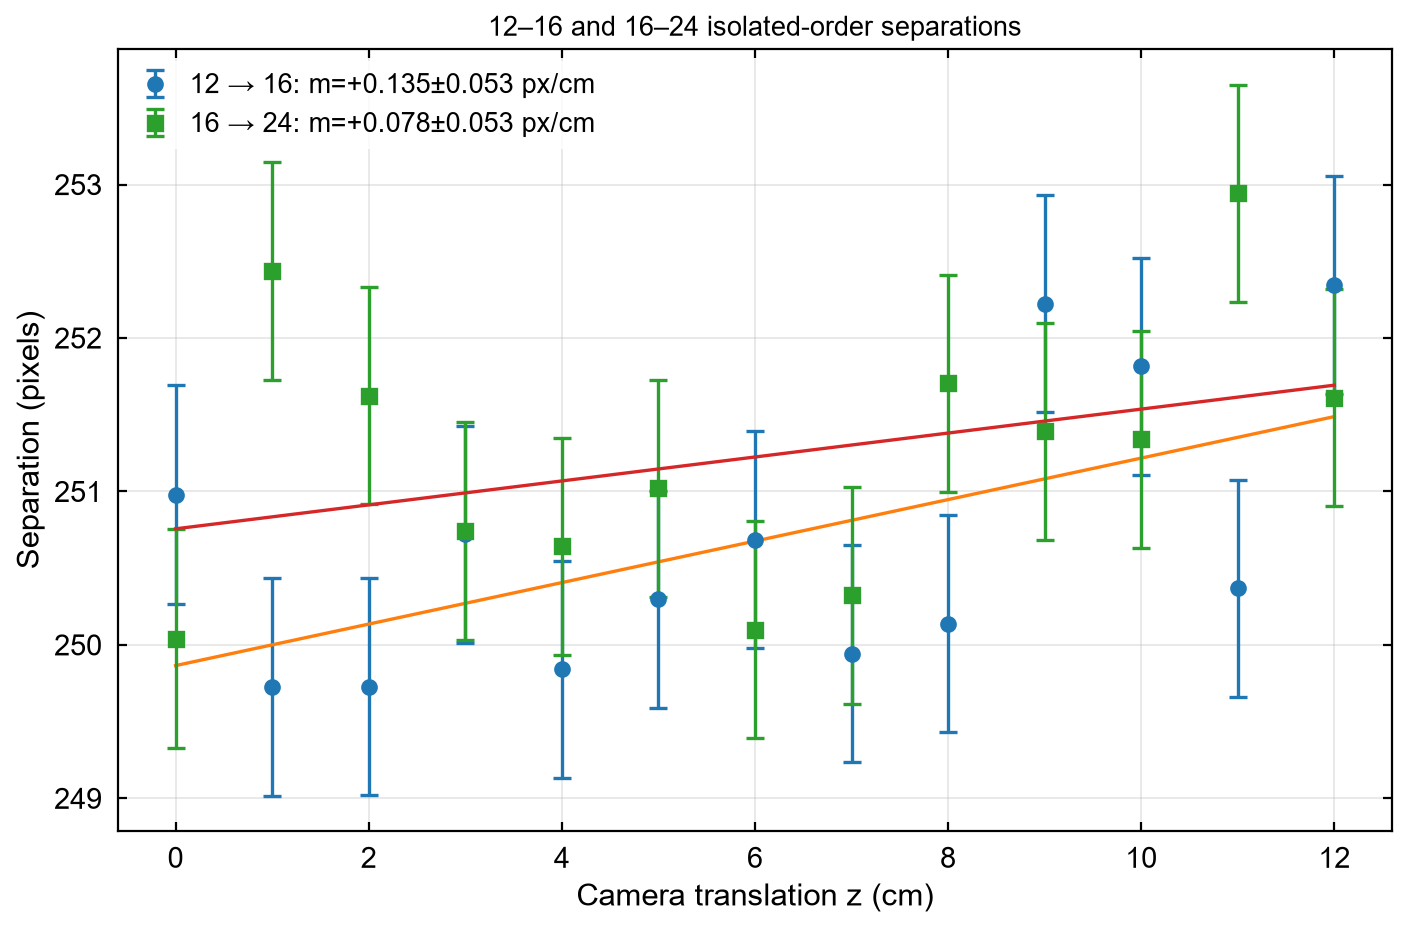

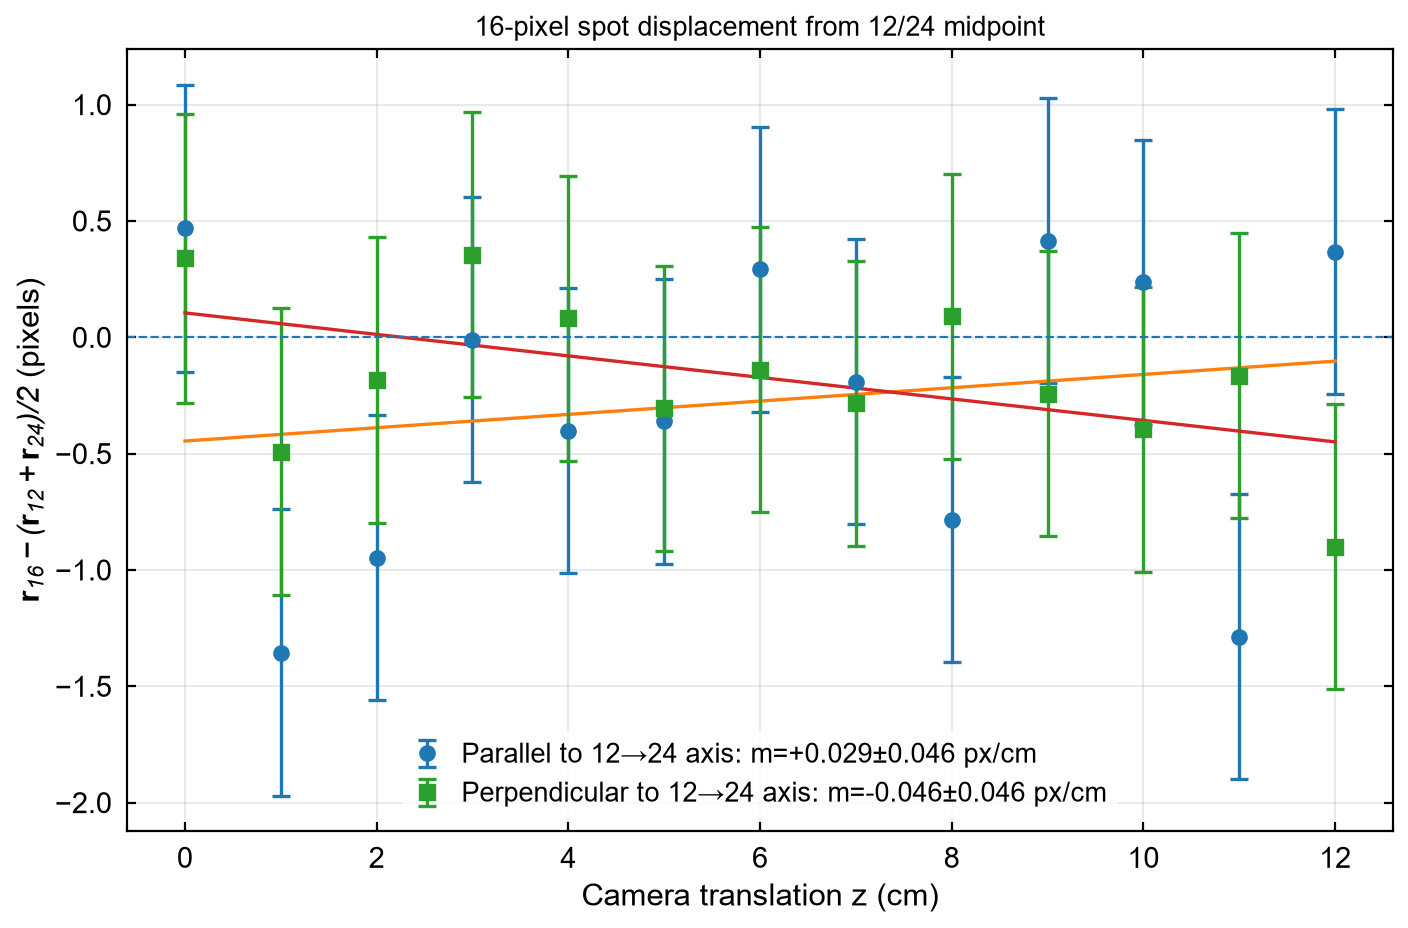

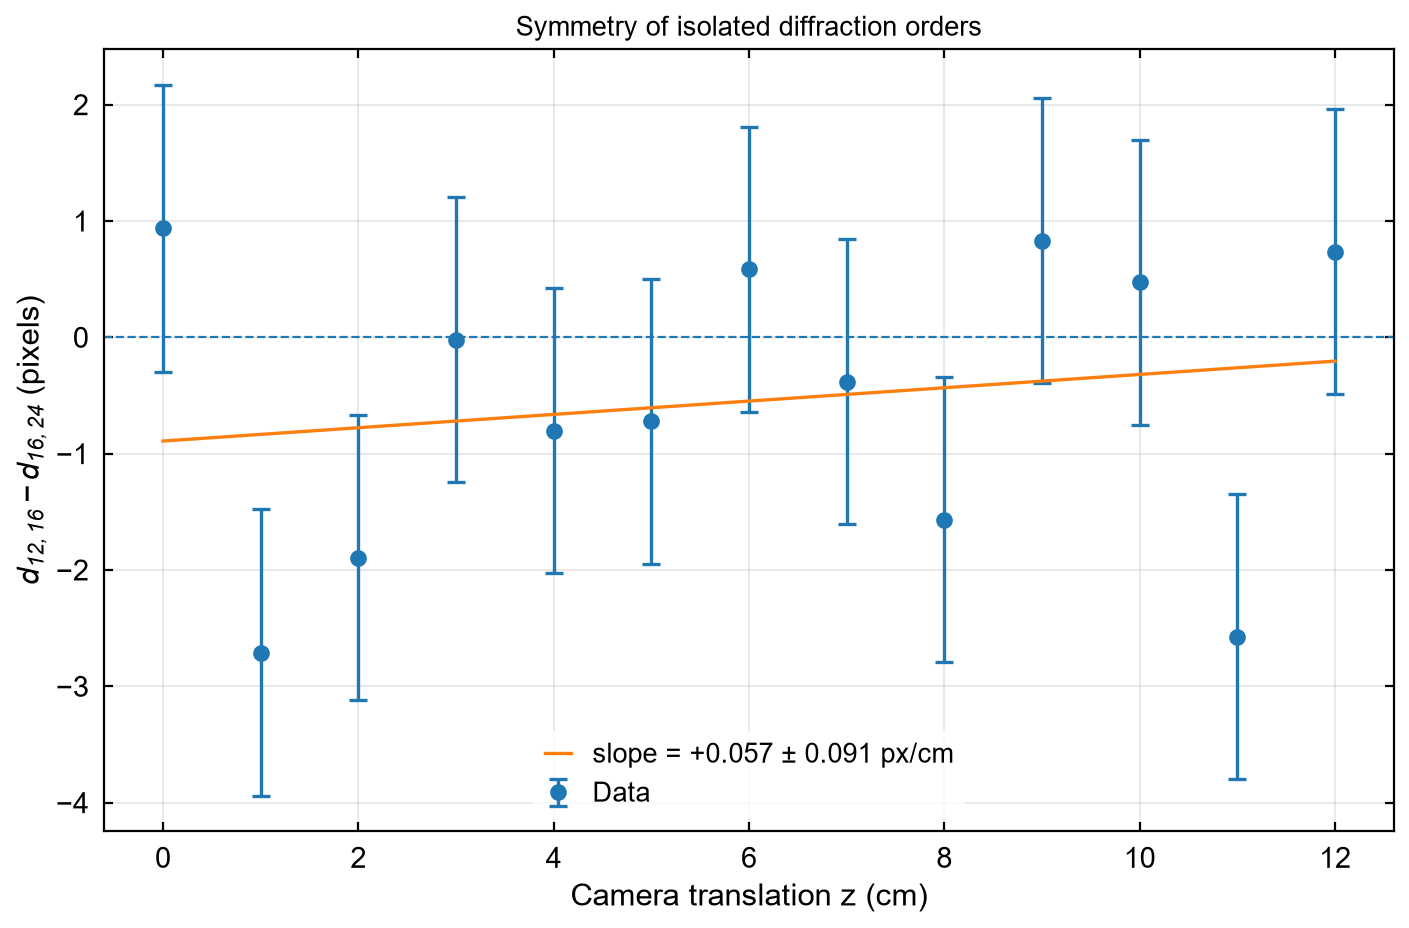

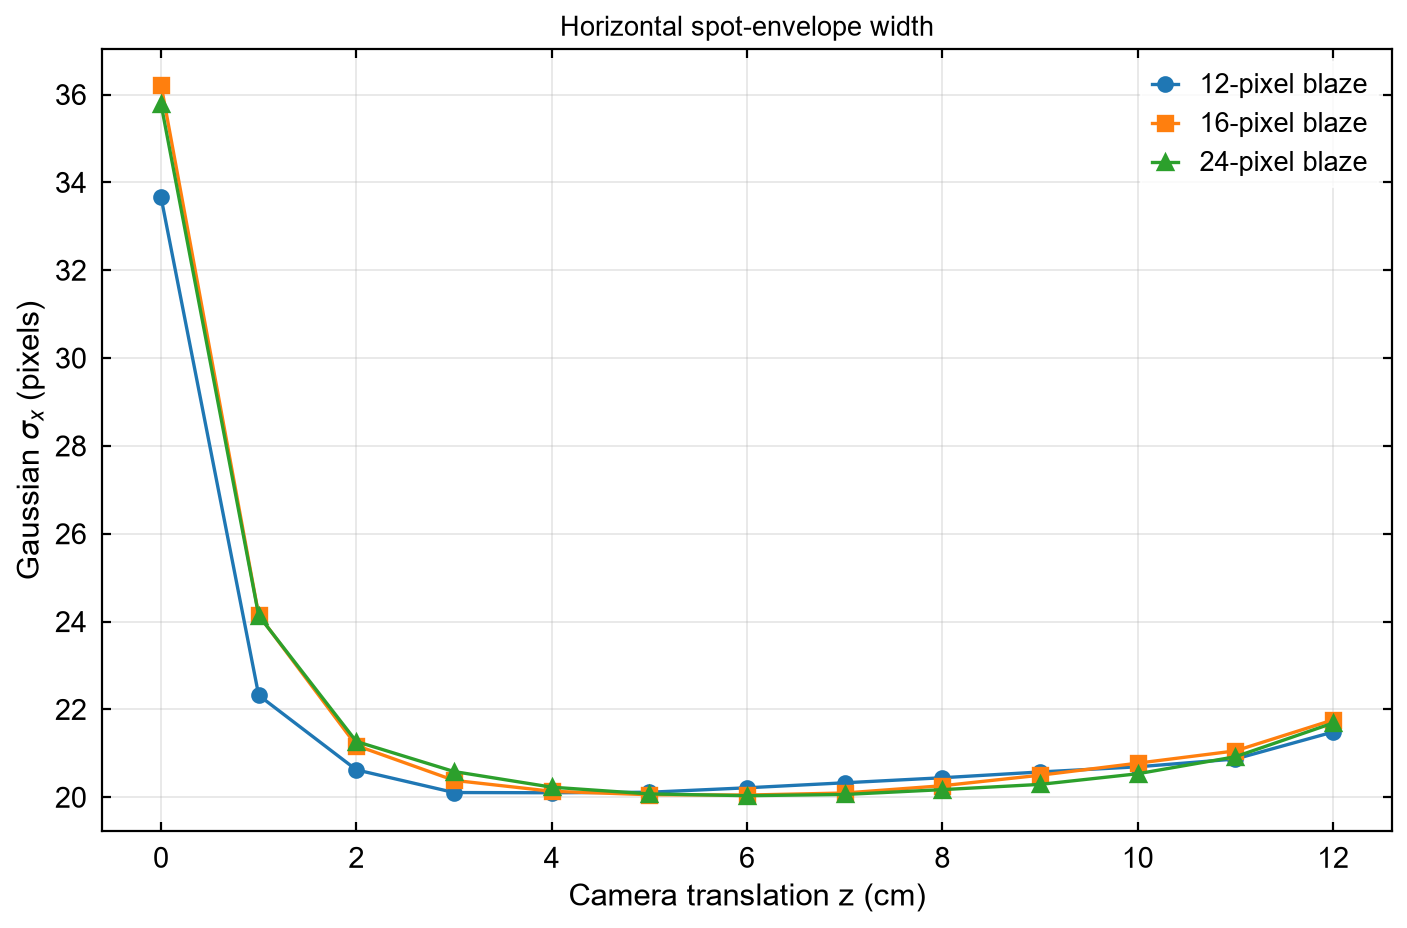

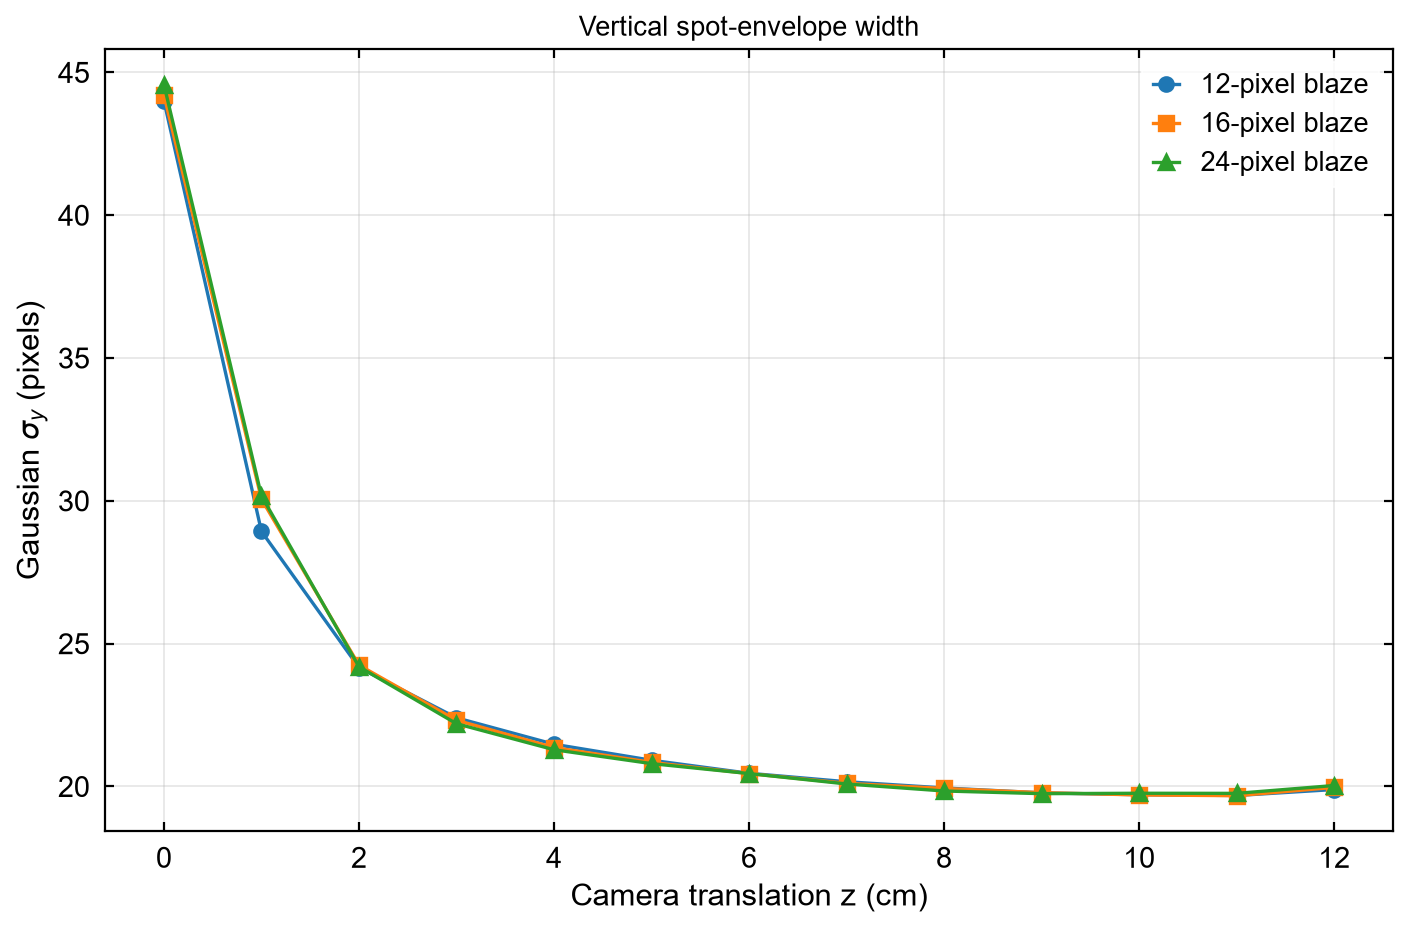



PHYSICAL SUMMARY — WEIGHTED FITS

12→16 slope = +0.13524 ± 0.05255 px/cm
16→24 slope = +0.07802 ± 0.05256 px/cm
12→24 slope = +0.21317 ± 0.05256 px/cm

Midpoint-parallel slope = +0.02863 ± 0.04552 px/cm
Midpoint-perpendicular slope = -0.04619 ± 0.04559 px/cm
Asymmetry slope = +0.05725 ± 0.09104 px/cm

Mean absolute midpoint-parallel error = 0.548 px


IMPORTANT INTERPRETATION NOTE

Formal covariance errors come from fitting the smoothed Gaussian envelope.
Because smoothing introduces correlated pixels and the actual spot is not perfectly Gaussian,
the formal covariance errors alone are probably too optimistic.

The plots therefore use:
sigma_effective = sqrt(sigma_formal^2 + systematic_floor^2)

Current systematic centroid floor = 0.500 px

For the most defensible experimental uncertainty, take several repeated images at the same z/blaze and measure the repeatability of the fitted center.

Finished.


In [7]:
# ============================================================
# ISOLATED 12 / 16 / 24 PIXEL BLAZE PROPAGATION ANALYSIS
#
# Expected filenames:
#
#   z0-12.bmp
#   z0-16.bmp
#   z0-24.bmp
#   z1-12.bmp
#   ...
#   z12-24.bmp
#
# z is camera translation in cm.
#
# IMPORTANT:
#   z=0 is NOT the lens plane.
#   In your experiment z=0 is already approximately 20 cm
#   downstream of the lens.
#
# Increasing z means camera moves farther away from the lens.
# ============================================================


from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from scipy.ndimage import gaussian_filter
from scipy.optimize import curve_fit


# ============================================================
# USER SETTINGS
# ============================================================

DATA_DIR = Path(
    r"C:\Users\admin\Desktop\Projects\SLM\SLM tests\Data\300 mm longitudinal\final locked position- one spot at a time to avoid phase intermod"
)

# Camera translation values
Z_VALUES = np.arange(0, 13, 1)       # z0 ... z12 [cm]

BLAZES = [12, 16, 24]


# ------------------------------------------------------------
# IMAGE PROCESSING
# ------------------------------------------------------------

# Smooth fine interference/fringe structure so that the fit
# follows the overall optical spot envelope.
SMOOTH_SIGMA_PX = 5.0

# Half-width of fitting ROI
ROI_HALF_SIZE = 90

# Show fit on every image?
SHOW_EVERY_FIT = False


# ------------------------------------------------------------
# CENTER UNCERTAINTY
# ------------------------------------------------------------
#
# curve_fit gives us a formal statistical error from pcov.
#
# However:
#   - image is smoothed
#   - neighboring pixels are correlated
#   - spot is not a perfect Gaussian
#   - fringes/non-Gaussian structure remain
#
# Therefore the formal pcov uncertainty will probably be
# unrealistically small.
#
# We therefore define:
#
# sigma_effective^2 =
#     sigma_formal^2 + sigma_systematic_floor^2
#
# Set this to 0.0 if you want PURELY formal curve_fit errors.
#
# 0.5 px is a reasonable starting conservative value.
# Later, repeated images would give a much better estimate.
# ------------------------------------------------------------

CENTER_SYSTEMATIC_FLOOR_PX = 0.5


# ============================================================
# HELPER FUNCTIONS
# ============================================================

def load_image(path):
    """Load BMP as floating-point numpy array."""
    return np.asarray(Image.open(path), dtype=float)


# ------------------------------------------------------------
# 2D Gaussian model
# ------------------------------------------------------------

def gaussian_2d(coords, amplitude, x0, y0, sx, sy, offset):

    x, y = coords

    g = (
        offset
        + amplitude
        * np.exp(
            -(
                (x - x0)**2 / (2 * sx**2)
                + (y - y0)**2 / (2 * sy**2)
            )
        )
    )

    return g.ravel()


# ------------------------------------------------------------
# FIT SPOT CENTER
# ------------------------------------------------------------

def fit_spot_center(path, show=False):
    """
    Fit the overall optical spot envelope.

    Procedure:
        1. Load image
        2. Estimate/subtract background
        3. Smooth fine fringe structure
        4. Find approximate peak
        5. Crop ROI
        6. Fit smoothed ROI with axis-aligned 2D Gaussian
        7. Extract formal covariance uncertainty on x0, y0

    Returns
    -------
    x0, y0
        fitted center [pixels]

    x0_formal_err, y0_formal_err
        formal 1-sigma uncertainties from curve_fit covariance

    sx, sy
        Gaussian widths [pixels]

    Notes
    -----
    sx and sy are NOT center uncertainties.
    """

    image = load_image(path)

    # --------------------------------------------------------
    # Background subtraction
    # --------------------------------------------------------

    background = np.percentile(image, 10)

    clean = image - background
    clean[clean < 0] = 0


    # --------------------------------------------------------
    # Smooth fine fringe structure
    # --------------------------------------------------------

    smooth = gaussian_filter(
        clean,
        sigma=SMOOTH_SIGMA_PX
    )


    # --------------------------------------------------------
    # Find approximate center
    # --------------------------------------------------------

    y_peak, x_peak = np.unravel_index(
        np.argmax(smooth),
        smooth.shape
    )

    ny, nx = smooth.shape


    # --------------------------------------------------------
    # ROI
    # --------------------------------------------------------

    x_min = max(0, x_peak - ROI_HALF_SIZE)
    x_max = min(nx, x_peak + ROI_HALF_SIZE + 1)

    y_min = max(0, y_peak - ROI_HALF_SIZE)
    y_max = min(ny, y_peak + ROI_HALF_SIZE + 1)

    roi = smooth[
        y_min:y_max,
        x_min:x_max
    ]


    # --------------------------------------------------------
    # Coordinate arrays
    # --------------------------------------------------------

    yy, xx = np.indices(roi.shape)

    xx_full = xx + x_min
    yy_full = yy + y_min


    # --------------------------------------------------------
    # Initial parameters
    # --------------------------------------------------------

    amp0 = roi.max() - np.median(roi)

    p0 = [
        amp0,
        float(x_peak),
        float(y_peak),
        20.0,
        20.0,
        float(np.median(roi)),
    ]


    bounds_lower = [
        0,
        x_min,
        y_min,
        2,
        2,
        -np.inf,
    ]


    bounds_upper = [
        np.inf,
        x_max,
        y_max,
        ROI_HALF_SIZE,
        ROI_HALF_SIZE,
        np.inf,
    ]


    # --------------------------------------------------------
    # Gaussian fit
    # --------------------------------------------------------

    popt, pcov = curve_fit(
        gaussian_2d,
        (xx_full, yy_full),
        roi.ravel(),
        p0=p0,
        bounds=(bounds_lower, bounds_upper),
        maxfev=30000,
    )


    amplitude, x0, y0, sx, sy, offset = popt


    # --------------------------------------------------------
    # Formal parameter uncertainties
    # --------------------------------------------------------

    perr = np.sqrt(np.diag(pcov))

    x0_formal_err = perr[1]
    y0_formal_err = perr[2]


    # --------------------------------------------------------
    # OPTIONAL FIT DISPLAY
    # --------------------------------------------------------

    if show:

        fit_roi = gaussian_2d(
            (xx_full, yy_full),
            *popt
        ).reshape(roi.shape)


        plt.figure(figsize=(8, 5))

        plt.imshow(
            image,
            origin="upper"
        )

        plt.scatter(
            [x0],
            [y0],
            marker="+",
            s=150,
            linewidths=2,
            label=(
                f"x = {x0:.3f} ± {x0_formal_err:.3f} px\n"
                f"y = {y0:.3f} ± {y0_formal_err:.3f} px"
            )
        )

        plt.xlim(x_min, x_max)
        plt.ylim(y_max, y_min)

        plt.title(path.name)

        plt.legend()
        plt.tight_layout()
        plt.show()


    return (
        x0,
        y0,
        x0_formal_err,
        y0_formal_err,
        sx,
        sy,
    )


# ============================================================
# DISTANCE FUNCTIONS
# ============================================================

def distance(p1, p2):
    """2D Euclidean distance."""

    p1 = np.asarray(p1, dtype=float)
    p2 = np.asarray(p2, dtype=float)

    return np.linalg.norm(p2 - p1)


def distance_with_error(p1, p2, e1, e2):
    """
    Euclidean distance and propagated uncertainty.

    Parameters
    ----------
    p1, p2
        [x, y]

    e1, e2
        [sigma_x, sigma_y]

    Assumes independent x/y errors.
    """

    p1 = np.asarray(p1, dtype=float)
    p2 = np.asarray(p2, dtype=float)

    e1 = np.asarray(e1, dtype=float)
    e2 = np.asarray(e2, dtype=float)


    dx = p2[0] - p1[0]
    dy = p2[1] - p1[1]

    d = np.sqrt(
        dx**2 + dy**2
    )


    if d == 0:
        return 0.0, np.nan


    variance = (
        (dx / d)**2
        * (
            e1[0]**2
            + e2[0]**2
        )
        +
        (dy / d)**2
        * (
            e1[1]**2
            + e2[1]**2
        )
    )


    sigma_d = np.sqrt(variance)

    return d, sigma_d


# ============================================================
# ASYMMETRY ERROR
# ============================================================

def asymmetry_with_error(
    p12,
    p16,
    p24,
    e12,
    e16,
    e24,
):
    """
    Calculate

        A = d(12,16) - d(16,24)

    and propagate the centroid uncertainties correctly.

    This explicitly accounts for the fact that the 16-pixel
    centroid occurs in BOTH distances.
    """

    p12 = np.asarray(p12, dtype=float)
    p16 = np.asarray(p16, dtype=float)
    p24 = np.asarray(p24, dtype=float)

    e12 = np.asarray(e12, dtype=float)
    e16 = np.asarray(e16, dtype=float)
    e24 = np.asarray(e24, dtype=float)


    v1 = p16 - p12
    v2 = p24 - p16

    d1 = np.linalg.norm(v1)
    d2 = np.linalg.norm(v2)


    u1 = v1 / d1
    u2 = v2 / d2


    asymmetry = d1 - d2


    # Gradient of A wrt:
    #
    # p12: -u1
    # p16:  u1 + u2
    # p24: -u2

    grad12 = -u1
    grad16 = u1 + u2
    grad24 = -u2


    variance = (

        grad12[0]**2 * e12[0]**2
        + grad12[1]**2 * e12[1]**2

        + grad16[0]**2 * e16[0]**2
        + grad16[1]**2 * e16[1]**2

        + grad24[0]**2 * e24[0]**2
        + grad24[1]**2 * e24[1]**2
    )


    sigma = np.sqrt(variance)

    return asymmetry, sigma


# ============================================================
# WEIGHTED LINEAR FIT
# ============================================================

def line_model(x, m, b):
    return m*x + b


def weighted_linear_fit(x, y, yerr):
    """
    Weighted fit:

        y = m*x + b

    using supplied 1-sigma y-errors.

    Returns:
        m
        b
        m_err
        b_err
        reduced_chi2
    """

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    yerr = np.asarray(yerr, dtype=float)


    # Protect against zero/invalid errors
    good = (
        np.isfinite(x)
        & np.isfinite(y)
        & np.isfinite(yerr)
        & (yerr > 0)
    )

    x_fit = x[good]
    y_fit = y[good]
    err_fit = yerr[good]


    # Initial estimate
    m0, b0 = np.polyfit(
        x_fit,
        y_fit,
        1
    )


    popt, pcov = curve_fit(
        line_model,
        x_fit,
        y_fit,
        sigma=err_fit,
        absolute_sigma=True,
        p0=[m0, b0]
    )


    m, b = popt

    m_err = np.sqrt(
        pcov[0, 0]
    )

    b_err = np.sqrt(
        pcov[1, 1]
    )


    residuals = (
        y_fit
        - line_model(
            x_fit,
            m,
            b
        )
    )


    chi2 = np.sum(
        (
            residuals
            / err_fit
        )**2
    )


    dof = len(x_fit) - 2

    if dof > 0:
        reduced_chi2 = chi2 / dof
    else:
        reduced_chi2 = np.nan


    return (
        m,
        b,
        m_err,
        b_err,
        reduced_chi2,
    )


# ============================================================
# FIND ALL CENTERS
# ============================================================

center_rows = []


for z in Z_VALUES:

    for blaze in BLAZES:

        filename = f"z{z}-{blaze}.bmp"

        path = (
            DATA_DIR
            / filename
        )


        if not path.exists():

            print(
                f"WARNING: missing {filename}"
            )

            continue


        (
            x0,
            y0,
            x0_formal_err,
            y0_formal_err,
            sx,
            sy,
        ) = fit_spot_center(
            path,
            show=SHOW_EVERY_FIT
        )


        # ----------------------------------------------------
        # Effective centroid uncertainty
        # ----------------------------------------------------
        #
        # formal covariance
        # +
        # systematic floor
        #
        # added in quadrature
        # ----------------------------------------------------

        x0_err = np.sqrt(
            x0_formal_err**2
            +
            CENTER_SYSTEMATIC_FLOOR_PX**2
        )

        y0_err = np.sqrt(
            y0_formal_err**2
            +
            CENTER_SYSTEMATIC_FLOOR_PX**2
        )


        center_rows.append(
            {
                "z_cm": z,
                "blaze_px": blaze,

                "x_px": x0,
                "y_px": y0,

                "x_formal_err_px":
                    x0_formal_err,

                "y_formal_err_px":
                    y0_formal_err,

                "x_err_px":
                    x0_err,

                "y_err_px":
                    y0_err,

                "sigma_x_px": sx,
                "sigma_y_px": sy,
            }
        )


centers = pd.DataFrame(
    center_rows
)


print(
    "\n================ CENTERS ================\n"
)

print(
    centers.to_string(index=False)
)


# ============================================================
# PRINT FORMAL ERROR STATISTICS
# ============================================================

print("\n")
print("=" * 75)
print("CENTER UNCERTAINTY STATISTICS")
print("=" * 75)


print(
    "\nMedian formal x-center uncertainty:"
)

print(
    f"{np.median(centers['x_formal_err_px']):.5f} px"
)


print(
    "\nMedian formal y-center uncertainty:"
)

print(
    f"{np.median(centers['y_formal_err_px']):.5f} px"
)


print(
    "\nSystematic center-error floor:"
)

print(
    f"{CENTER_SYSTEMATIC_FLOOR_PX:.3f} px"
)


print(
    "\nMedian effective x-center uncertainty:"
)

print(
    f"{np.median(centers['x_err_px']):.5f} px"
)


print(
    "\nMedian effective y-center uncertainty:"
)

print(
    f"{np.median(centers['y_err_px']):.5f} px"
)


# ============================================================
# CALCULATE DISTANCES + MIDPOINT ERROR
# ============================================================

analysis_rows = []


for z in sorted(
    centers["z_cm"].unique()
):


    sub = centers[
        centers["z_cm"] == z
    ]


    if not all(
        blaze in sub["blaze_px"].values
        for blaze in BLAZES
    ):

        print(
            f"Skipping z={z}: incomplete triplet"
        )

        continue


    # ========================================================
    # POSITIONS
    # ========================================================

    p12 = (
        sub[
            sub["blaze_px"] == 12
        ][
            ["x_px", "y_px"]
        ]
        .iloc[0]
        .to_numpy(dtype=float)
    )


    p16 = (
        sub[
            sub["blaze_px"] == 16
        ][
            ["x_px", "y_px"]
        ]
        .iloc[0]
        .to_numpy(dtype=float)
    )


    p24 = (
        sub[
            sub["blaze_px"] == 24
        ][
            ["x_px", "y_px"]
        ]
        .iloc[0]
        .to_numpy(dtype=float)
    )


    # ========================================================
    # POSITION UNCERTAINTIES
    # ========================================================

    e12 = (
        sub[
            sub["blaze_px"] == 12
        ][
            ["x_err_px", "y_err_px"]
        ]
        .iloc[0]
        .to_numpy(dtype=float)
    )


    e16 = (
        sub[
            sub["blaze_px"] == 16
        ][
            ["x_err_px", "y_err_px"]
        ]
        .iloc[0]
        .to_numpy(dtype=float)
    )


    e24 = (
        sub[
            sub["blaze_px"] == 24
        ][
            ["x_err_px", "y_err_px"]
        ]
        .iloc[0]
        .to_numpy(dtype=float)
    )


    # ========================================================
    # PAIRWISE DISTANCES
    # ========================================================

    (
        d12_16,
        d12_16_err,
    ) = distance_with_error(
        p12,
        p16,
        e12,
        e16
    )


    (
        d16_24,
        d16_24_err,
    ) = distance_with_error(
        p16,
        p24,
        e16,
        e24
    )


    (
        d12_24,
        d12_24_err,
    ) = distance_with_error(
        p12,
        p24,
        e12,
        e24
    )


    # ========================================================
    # MIDPOINT
    # ========================================================

    midpoint = (
        0.5
        * (
            p12
            + p24
        )
    )


    midpoint_vector = (
        p16
        - midpoint
    )


    midpoint_error = (
        np.linalg.norm(
            midpoint_vector
        )
    )


    # ========================================================
    # MIDPOINT COVARIANCE
    # ========================================================
    #
    # Delta =
    #
    # p16 - (p12+p24)/2
    #
    # assuming independent measurements
    # ========================================================

    midpoint_var_x = (
        e16[0]**2
        +
        0.25 * e12[0]**2
        +
        0.25 * e24[0]**2
    )


    midpoint_var_y = (
        e16[1]**2
        +
        0.25 * e12[1]**2
        +
        0.25 * e24[1]**2
    )


    # ========================================================
    # OUTER AXIS
    # ========================================================

    outer_vector = (
        p24
        - p12
    )


    outer_distance = (
        np.linalg.norm(
            outer_vector
        )
    )


    u_parallel = (
        outer_vector
        / outer_distance
    )


    u_perp = np.array(
        [
            -u_parallel[1],
            u_parallel[0],
        ]
    )


    # ========================================================
    # MIDPOINT COMPONENTS
    # ========================================================

    midpoint_parallel = np.dot(
        midpoint_vector,
        u_parallel
    )


    midpoint_perpendicular = np.dot(
        midpoint_vector,
        u_perp
    )


    # --------------------------------------------------------
    # Error propagation
    #
    # Treat u_parallel/u_perp as fixed.
    #
    # Their uncertainty is negligible compared with centroid
    # errors because outer spots are ~500 px apart.
    # --------------------------------------------------------

    midpoint_parallel_err = np.sqrt(
        u_parallel[0]**2
        * midpoint_var_x
        +
        u_parallel[1]**2
        * midpoint_var_y
    )


    midpoint_perpendicular_err = np.sqrt(
        u_perp[0]**2
        * midpoint_var_x
        +
        u_perp[1]**2
        * midpoint_var_y
    )


    # --------------------------------------------------------
    # Magnitude midpoint error uncertainty
    # --------------------------------------------------------

    if midpoint_error > 0:

        midpoint_error_err = np.sqrt(

            (
                midpoint_vector[0]
                / midpoint_error
            )**2
            * midpoint_var_x

            +

            (
                midpoint_vector[1]
                / midpoint_error
            )**2
            * midpoint_var_y
        )

    else:

        midpoint_error_err = np.sqrt(
            midpoint_var_x
            + midpoint_var_y
        )


    # ========================================================
    # DISTANCE ASYMMETRY
    # ========================================================

    (
        asymmetry,
        asymmetry_err,
    ) = asymmetry_with_error(
        p12,
        p16,
        p24,
        e12,
        e16,
        e24,
    )


    # ========================================================
    # STORE
    # ========================================================

    analysis_rows.append(
        {
            "z_cm": z,

            "x12": p12[0],
            "y12": p12[1],

            "x16": p16[0],
            "y16": p16[1],

            "x24": p24[0],
            "y24": p24[1],


            "d12_16_px":
                d12_16,

            "d12_16_err_px":
                d12_16_err,


            "d16_24_px":
                d16_24,

            "d16_24_err_px":
                d16_24_err,


            "d12_24_px":
                d12_24,

            "d12_24_err_px":
                d12_24_err,


            "midpoint_error_px":
                midpoint_error,

            "midpoint_error_err_px":
                midpoint_error_err,


            "midpoint_parallel_px":
                midpoint_parallel,

            "midpoint_parallel_err_px":
                midpoint_parallel_err,


            "midpoint_perpendicular_px":
                midpoint_perpendicular,

            "midpoint_perpendicular_err_px":
                midpoint_perpendicular_err,


            "distance_asymmetry_px":
                asymmetry,

            "distance_asymmetry_err_px":
                asymmetry_err,
        }
    )


results = pd.DataFrame(
    analysis_rows
)


print(
    "\n================ DISTANCE ANALYSIS ================\n"
)

print(
    results.to_string(index=False)
)


# ============================================================
# SAVE CSV FILES
# ============================================================

centers.to_csv(
    DATA_DIR
    / "isolated_spot_centers_with_errors.csv",
    index=False
)


results.to_csv(
    DATA_DIR
    / "isolated_spot_analysis_with_errors.csv",
    index=False
)


# ============================================================
# PLOT 0A:
# X CENTER TRAJECTORIES WITH ERROR BARS
# ============================================================

plt.figure(figsize=(9, 6))


for blaze, marker in [
    (12, "o"),
    (16, "s"),
    (24, "^"),
]:

    sub = centers[
        centers["blaze_px"] == blaze
    ]


    plt.errorbar(
        sub["z_cm"],
        sub["x_px"],
        yerr=sub["x_err_px"],
        fmt=marker,
        linestyle="-",
        capsize=4,
        markersize=5,
        label=f"{blaze}-pixel blaze"
    )


plt.xlabel(
    "Camera translation z (cm)"
)

plt.ylabel(
    "Fitted x center (pixels)"
)

plt.title(
    "X-center trajectories"
)

plt.grid(alpha=0.3)

plt.legend()

plt.tight_layout()

plt.savefig(
    DATA_DIR
    / "isolated_x_centers_vs_z.png",
    dpi=200
)

plt.show()


# ============================================================
# PLOT 0B:
# Y CENTER TRAJECTORIES WITH ERROR BARS
# ============================================================

plt.figure(figsize=(9, 6))


for blaze, marker in [
    (12, "o"),
    (16, "s"),
    (24, "^"),
]:

    sub = centers[
        centers["blaze_px"] == blaze
    ]


    plt.errorbar(
        sub["z_cm"],
        sub["y_px"],
        yerr=sub["y_err_px"],
        fmt=marker,
        linestyle="-",
        capsize=4,
        markersize=5,
        label=f"{blaze}-pixel blaze"
    )


plt.xlabel(
    "Camera translation z (cm)"
)

plt.ylabel(
    "Fitted y center (pixels)"
)

plt.title(
    "Y-center trajectories"
)

plt.grid(alpha=0.3)

plt.legend()

plt.tight_layout()

plt.savefig(
    DATA_DIR
    / "isolated_y_centers_vs_z.png",
    dpi=200
)

plt.show()


# ============================================================
# PREPARE FITS
# ============================================================

z = results[
    "z_cm"
].to_numpy(dtype=float)


fit_quantities = {

    "d12-16": (
        "d12_16_px",
        "d12_16_err_px"
    ),

    "d16-24": (
        "d16_24_px",
        "d16_24_err_px"
    ),

    "d12-24": (
        "d12_24_px",
        "d12_24_err_px"
    ),

    "midpoint parallel": (
        "midpoint_parallel_px",
        "midpoint_parallel_err_px"
    ),

    "midpoint perpendicular": (
        "midpoint_perpendicular_px",
        "midpoint_perpendicular_err_px"
    ),

    "distance asymmetry": (
        "distance_asymmetry_px",
        "distance_asymmetry_err_px"
    ),
}


fit_results = {}


print("\n")
print("=" * 90)
print("WEIGHTED LINEAR FIT RESULTS")
print("=" * 90)


for name, (
    value_column,
    error_column,
) in fit_quantities.items():


    y = results[
        value_column
    ].to_numpy(dtype=float)


    yerr = results[
        error_column
    ].to_numpy(dtype=float)


    (
        m,
        b,
        m_err,
        b_err,
        red_chi2,
    ) = weighted_linear_fit(
        z,
        y,
        yerr
    )


    fit_results[name] = {
        "slope": m,
        "slope_err": m_err,
        "intercept": b,
        "intercept_err": b_err,
        "reduced_chi2": red_chi2,
    }


    print(
        f"{name:25s}: "
        f"slope = {m:+.5f} ± {m_err:.5f} px/cm   "
        f"reduced chi² = {red_chi2:.3f}"
    )


# ============================================================
# PLOT 1:
# ALL THREE DISTANCES + ERROR BARS
# ============================================================

plt.figure(figsize=(9, 6))


plot_info = [

    (
        "12 → 16",
        "d12_16_px",
        "d12_16_err_px",
        "o"
    ),

    (
        "16 → 24",
        "d16_24_px",
        "d16_24_err_px",
        "s"
    ),

    (
        "12 → 24",
        "d12_24_px",
        "d12_24_err_px",
        "^"
    ),
]


for (
    name,
    column,
    error_column,
    marker,
) in plot_info:


    y = results[
        column
    ].to_numpy(dtype=float)


    yerr = results[
        error_column
    ].to_numpy(dtype=float)


    (
        m,
        b,
        m_err,
        b_err,
        red_chi2,
    ) = weighted_linear_fit(
        z,
        y,
        yerr
    )


    plt.errorbar(
        z,
        y,
        yerr=yerr,
        fmt=marker,
        linestyle="none",
        capsize=4,
        markersize=6,
        label=(
            f"{name}: "
            f"m={m:+.3f}±{m_err:.3f} px/cm"
        )
    )


    z_fit = np.linspace(
        z.min(),
        z.max(),
        300
    )


    plt.plot(
        z_fit,
        m*z_fit + b
    )


plt.xlabel(
    "Camera translation z (cm)"
)

plt.ylabel(
    "2D spot separation (pixels)"
)

plt.title(
    "Propagation of isolated diffraction orders"
)

plt.grid(alpha=0.3)

plt.legend()

plt.tight_layout()

plt.savefig(
    DATA_DIR
    / "isolated_distances_vs_z_with_errors.png",
    dpi=200
)

plt.show()


# ============================================================
# PLOT 2:
# TWO HALF-DISTANCES
# ============================================================

plt.figure(figsize=(9, 6))


plot_info = [

    (
        "12 → 16",
        "d12_16_px",
        "d12_16_err_px",
        "o"
    ),

    (
        "16 → 24",
        "d16_24_px",
        "d16_24_err_px",
        "s"
    ),
]


for (
    name,
    column,
    error_column,
    marker,
) in plot_info:


    y = results[
        column
    ].to_numpy(dtype=float)


    yerr = results[
        error_column
    ].to_numpy(dtype=float)


    (
        m,
        b,
        m_err,
        b_err,
        red_chi2,
    ) = weighted_linear_fit(
        z,
        y,
        yerr
    )


    plt.errorbar(
        z,
        y,
        yerr=yerr,
        fmt=marker,
        linestyle="none",
        capsize=4,
        markersize=6,
        label=(
            f"{name}: "
            f"m={m:+.3f}±{m_err:.3f} px/cm"
        )
    )


    z_fit = np.linspace(
        z.min(),
        z.max(),
        300
    )


    plt.plot(
        z_fit,
        m*z_fit + b
    )


plt.xlabel(
    "Camera translation z (cm)"
)

plt.ylabel(
    "Separation (pixels)"
)

plt.title(
    "12–16 and 16–24 isolated-order separations"
)

plt.grid(alpha=0.3)

plt.legend()

plt.tight_layout()

plt.savefig(
    DATA_DIR
    / "isolated_half_distances_vs_z_with_errors.png",
    dpi=200
)

plt.show()


# ============================================================
# PLOT 3:
# MIDPOINT COMPONENTS
# ============================================================

plt.figure(figsize=(9, 6))


plot_info = [

    (
        "Parallel to 12→24 axis",
        "midpoint_parallel_px",
        "midpoint_parallel_err_px",
        "o"
    ),

    (
        "Perpendicular to 12→24 axis",
        "midpoint_perpendicular_px",
        "midpoint_perpendicular_err_px",
        "s"
    ),
]


for (
    name,
    column,
    error_column,
    marker,
) in plot_info:


    y = results[
        column
    ].to_numpy(dtype=float)


    yerr = results[
        error_column
    ].to_numpy(dtype=float)


    (
        m,
        b,
        m_err,
        b_err,
        red_chi2,
    ) = weighted_linear_fit(
        z,
        y,
        yerr
    )


    plt.errorbar(
        z,
        y,
        yerr=yerr,
        fmt=marker,
        linestyle="none",
        capsize=4,
        markersize=6,
        label=(
            f"{name}: "
            f"m={m:+.3f}±{m_err:.3f} px/cm"
        )
    )


    z_fit = np.linspace(
        z.min(),
        z.max(),
        300
    )


    plt.plot(
        z_fit,
        m*z_fit + b
    )


plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)


plt.xlabel(
    "Camera translation z (cm)"
)


plt.ylabel(
    r"$\mathbf{r}_{16}-(\mathbf{r}_{12}+\mathbf{r}_{24})/2$ (pixels)"
)


plt.title(
    "16-pixel spot displacement from 12/24 midpoint"
)

plt.grid(alpha=0.3)

plt.legend()

plt.tight_layout()

plt.savefig(
    DATA_DIR
    / "isolated_midpoint_error_vs_z_with_errors.png",
    dpi=200
)

plt.show()


# ============================================================
# PLOT 4:
# DISTANCE ASYMMETRY
# ============================================================

asym = results[
    "distance_asymmetry_px"
].to_numpy(dtype=float)


asym_err = results[
    "distance_asymmetry_err_px"
].to_numpy(dtype=float)


(
    m,
    b,
    m_err,
    b_err,
    red_chi2,
) = weighted_linear_fit(
    z,
    asym,
    asym_err
)


plt.figure(
    figsize=(9, 6)
)


plt.errorbar(
    z,
    asym,
    yerr=asym_err,
    fmt="o",
    linestyle="none",
    capsize=4,
    markersize=6,
    label="Data"
)


z_fit = np.linspace(
    z.min(),
    z.max(),
    300
)


plt.plot(
    z_fit,
    m*z_fit+b,
    label=(
        f"slope = "
        f"{m:+.3f} ± {m_err:.3f} px/cm"
    )
)


plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)


plt.xlabel(
    "Camera translation z (cm)"
)


plt.ylabel(
    r"$d_{12,16}-d_{16,24}$ (pixels)"
)


plt.title(
    "Symmetry of isolated diffraction orders"
)


plt.grid(alpha=0.3)

plt.legend()

plt.tight_layout()


plt.savefig(
    DATA_DIR
    / "isolated_distance_asymmetry_vs_z_with_errors.png",
    dpi=200
)


plt.show()


# ============================================================
# PLOT 5:
# GAUSSIAN SPOT WIDTHS
# ============================================================

plt.figure(
    figsize=(9, 6)
)


for blaze, marker in [
    (12, "o"),
    (16, "s"),
    (24, "^"),
]:

    sub = centers[
        centers["blaze_px"] == blaze
    ]


    plt.plot(
        sub["z_cm"],
        sub["sigma_x_px"],
        marker=marker,
        label=f"{blaze}-pixel blaze"
    )


plt.xlabel(
    "Camera translation z (cm)"
)

plt.ylabel(
    r"Gaussian $\sigma_x$ (pixels)"
)

plt.title(
    "Horizontal spot-envelope width"
)

plt.grid(alpha=0.3)

plt.legend()

plt.tight_layout()

plt.savefig(
    DATA_DIR
    / "isolated_sigma_x_vs_z.png",
    dpi=200
)

plt.show()


plt.figure(
    figsize=(9, 6)
)


for blaze, marker in [
    (12, "o"),
    (16, "s"),
    (24, "^"),
]:

    sub = centers[
        centers["blaze_px"] == blaze
    ]


    plt.plot(
        sub["z_cm"],
        sub["sigma_y_px"],
        marker=marker,
        label=f"{blaze}-pixel blaze"
    )


plt.xlabel(
    "Camera translation z (cm)"
)

plt.ylabel(
    r"Gaussian $\sigma_y$ (pixels)"
)

plt.title(
    "Vertical spot-envelope width"
)

plt.grid(alpha=0.3)

plt.legend()

plt.tight_layout()

plt.savefig(
    DATA_DIR
    / "isolated_sigma_y_vs_z.png",
    dpi=200
)

plt.show()


# ============================================================
# FINAL SUMMARY
# ============================================================

m1 = fit_results[
    "d12-16"
]["slope"]

e1 = fit_results[
    "d12-16"
]["slope_err"]


m2 = fit_results[
    "d16-24"
]["slope"]

e2 = fit_results[
    "d16-24"
]["slope_err"]


m_outer = fit_results[
    "d12-24"
]["slope"]

e_outer = fit_results[
    "d12-24"
]["slope_err"]


m_mid = fit_results[
    "midpoint parallel"
]["slope"]

e_mid = fit_results[
    "midpoint parallel"
]["slope_err"]


m_mid_perp = fit_results[
    "midpoint perpendicular"
]["slope"]

e_mid_perp = fit_results[
    "midpoint perpendicular"
]["slope_err"]


m_asym = fit_results[
    "distance asymmetry"
]["slope"]

e_asym = fit_results[
    "distance asymmetry"
]["slope_err"]


print("\n")
print("=" * 90)
print("PHYSICAL SUMMARY — WEIGHTED FITS")
print("=" * 90)


print(
    f"\n12→16 slope = "
    f"{m1:+.5f} ± {e1:.5f} px/cm"
)


print(
    f"16→24 slope = "
    f"{m2:+.5f} ± {e2:.5f} px/cm"
)


print(
    f"12→24 slope = "
    f"{m_outer:+.5f} ± {e_outer:.5f} px/cm"
)


print(
    f"\nMidpoint-parallel slope = "
    f"{m_mid:+.5f} ± {e_mid:.5f} px/cm"
)


print(
    f"Midpoint-perpendicular slope = "
    f"{m_mid_perp:+.5f} ± {e_mid_perp:.5f} px/cm"
)


print(
    f"Asymmetry slope = "
    f"{m_asym:+.5f} ± {e_asym:.5f} px/cm"
)


print(
    "\nMean absolute midpoint-parallel error = "
    f"{np.mean(np.abs(results['midpoint_parallel_px'])):.3f} px"
)


print("\n")
print("=" * 90)
print("IMPORTANT INTERPRETATION NOTE")
print("=" * 90)


print(
    "\nFormal covariance errors come from fitting the "
    "smoothed Gaussian envelope."
)


print(
    "Because smoothing introduces correlated pixels and "
    "the actual spot is not perfectly Gaussian,"
)


print(
    "the formal covariance errors alone are probably "
    "too optimistic."
)


print(
    "\nThe plots therefore use:"
)


print(
    "sigma_effective = sqrt("
    "sigma_formal^2 + systematic_floor^2)"
)


print(
    f"\nCurrent systematic centroid floor = "
    f"{CENTER_SYSTEMATIC_FLOOR_PX:.3f} px"
)


print(
    "\nFor the most defensible experimental uncertainty, "
    "take several repeated images at the same z/blaze and "
    "measure the repeatability of the fitted center."
)


print("\nFinished.")